# 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Pandas: 3.0.3
NumPy: 2.5.1
TensorFlow: 2.21.0


# 2. Memuat Data AQI

In [2]:
df = pd.read_parquet(
    "data/dataset_aqi_gabungan.parquet",
    columns=["updated_at", "device", "aqi"]
)

df["updated_at"] = pd.to_datetime(df["updated_at"])

df_sensor = df[
    df["device"] == "Jl. Lapangan Rajawali"
].copy()

aqi_harian = (
    df_sensor
    .set_index("updated_at")["aqi"]
    .resample("D")
    .mean()
    .dropna()
)

aqi_harian = aqi_harian.loc[
    "2025-11-03":"2026-02-18"
]

print("Jumlah data:", len(aqi_harian))
print("Tanggal awal:", aqi_harian.index.min())
print("Tanggal akhir:", aqi_harian.index.max())
print("Nilai kosong:", aqi_harian.isna().sum())

Jumlah data: 108
Tanggal awal: 2025-11-03 00:00:00
Tanggal akhir: 2026-02-18 00:00:00
Nilai kosong: 0


# 3. Membagi data training dan testing

In [3]:
# Pembagian data secara kronologis
jumlah_train = 86

train = aqi_harian.iloc[:jumlah_train]
test = aqi_harian.iloc[jumlah_train:]

print("Data training:", len(train))
print("Periode training:", train.index.min(), "sampai", train.index.max())

print("\nData testing:", len(test))
print("Periode testing:", test.index.min(), "sampai", test.index.max())

Data training: 86
Periode training: 2025-11-03 00:00:00 sampai 2026-01-27 00:00:00

Data testing: 22
Periode testing: 2026-01-28 00:00:00 sampai 2026-02-18 00:00:00


# 4. Melatih model sarima terbaik

In [4]:
# Model SARIMA terbaik dari eksperimen sebelumnya
model_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_sarima = model_sarima.fit(disp=False)

print(hasil_sarima.summary())

d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
d:\S2 Ilmu Komputer UB\Tesis\Coba Tesis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                               aqi   No. Observations:                   86
Model:             SARIMAX(1, 0, 1)x(0, 0, 1, 7)   Log Likelihood                -299.699
Date:                           Sun, 18 Oct 2026   AIC                            607.398
Time:                                   15:15:43   BIC                            616.773
Sample:                               11-03-2025   HQIC                           611.148
                                    - 01-27-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9163      0.038     24.392      0.000       0.843       0.990
ma.L1         -0.1220      0.123     -0.994

# 5. Menghitung residual training

In [16]:

# Prediksi fitted SARIMA pada data training
prediksi_train_sarima_final = hasil_sarima_final.get_prediction(
    start=0,
    end=len(train) - 1
).predicted_mean

# Samakan indeks tanggal
prediksi_train_sarima_final.index = train.index

# Hitung residual training
residual_train_final = train - prediksi_train_sarima_final

print("Jumlah residual:", len(residual_train_final))
print("Residual kosong:", residual_train_final.isna().sum())
print("\nLima residual pertama:")
print(residual_train_final.head())


Jumlah residual: 86
Residual kosong: 0

Lima residual pertama:
updated_at
2025-11-03    67.871795
2025-11-04    13.699091
2025-11-05     3.750335
2025-11-06   -23.498898
2025-11-07    10.781703
dtype: float64


# 6. Membuat data sequence residual LSTM

Residual dihitung dari:
et=yt-y't


Keterangan:
- yt: nilai AQI aktual pada data training.
- y't: nilai estimasi AQI dari SARIMA.
- et: residual yang akan dipelajari oleh LSTM.

In [18]:

# Scaling residual training
residual_values_final = residual_train_final.to_numpy().reshape(-1, 1)

scaler_residual_final = MinMaxScaler(feature_range=(0, 1))
residual_scaled_final = scaler_residual_final.fit_transform(
    residual_values_final
)

# Membuat sequence sepanjang 7 hari
X_residual_final = []
y_residual_final = []

for i in range(look_back, len(residual_scaled_final)):
    X_residual_final.append(
        residual_scaled_final[i-look_back:i, 0]
    )
    y_residual_final.append(residual_scaled_final[i, 0])

X_residual_final = np.array(X_residual_final)
y_residual_final = np.array(y_residual_final)

X_residual_final_lstm = X_residual_final.reshape(
    X_residual_final.shape[0],
    X_residual_final.shape[1],
    1
)

print("X residual:", X_residual_final_lstm.shape)
print("y residual:", y_residual_final.shape)


X residual: (79, 7, 1)
y residual: (79,)


menjadi 79 sequence Karena 7 residual pertama digunakan sebagai input untuk memprediksi residual ke-8. Proses ini berlanjut sampai residual ke-86.

# 7. Membangun dan melatih LSTM residual

- LSTM 32 unit: mempelajari pola residual dari tujuh hari sebelumnya.
- Dense(1): menghasilkan satu prediksi residual.
- EarlyStopping: menghentikan pelatihan jika val_loss tidak membaik selama 10 epoch.
- Seed 42: membantu membuat hasil eksperimen lebih konsisten saat dijalankan ulang.

In [19]:

# Menetapkan seed agar eksperimen lebih konsisten
tf.keras.utils.set_random_seed(42)

# Membangun model LSTM residual
model_residual_final = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(32, activation="tanh"),
    Dense(1)
])

model_residual_final.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error"
)

early_stop_final = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_residual_final = model_residual_final.fit(
    X_residual_final_lstm,
    y_residual_final,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop_final],
    verbose=1
)

print("Pelatihan LSTM residual selesai.")
print(
    "Jumlah epoch:",
    len(history_residual_final.history["loss"])
)
print(
    "Validation loss terbaik:",
    min(history_residual_final.history["val_loss"])
)


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0697 - val_loss: 0.0234
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0377 - val_loss: 0.0077
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0223 - val_loss: 0.0040
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0203 - val_loss: 0.0055
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0201 - val_loss: 0.0044
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0190 - val_loss: 0.0039
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0193 - val_loss: 0.0040
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0194 - val_loss: 0.0039
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0193 - val_loss: 0.0040
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0192 - val_loss: 0.0040
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0191 - val_loss: 0.0040
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0191 - val_lo

# 8. Memprediksi residual 22 hari kedepan

In [20]:

# Mengambil 7 residual training terakhir sebagai input awal
riwayat_residual = list(
    residual_scaled_final[-look_back:, 0]
)

prediksi_residual_scaled = []

# Prediksi residual secara berurutan untuk 22 hari
for _ in range(len(test)):
    input_lstm = np.array(
        riwayat_residual[-look_back:]
    ).reshape(1, look_back, 1)

    prediksi_satu_hari = model_residual_final.predict(
        input_lstm, verbose=0
    )[0, 0]

    prediksi_residual_scaled.append(prediksi_satu_hari)

    # Gunakan prediksi residual sebagai input hari berikutnya
    riwayat_residual.append(prediksi_satu_hari)

# Kembalikan residual ke skala aslinya
prediksi_residual = scaler_residual_final.inverse_transform(
    np.array(prediksi_residual_scaled).reshape(-1, 1)
).flatten()

# Simpan sebagai Series dengan indeks tanggal testing
prediksi_residual_test = pd.Series(
    prediksi_residual,
    index=test.index,
    name="Prediksi_Residual_LSTM"
)

print("Jumlah prediksi residual:", len(prediksi_residual_test))
print("\nLima prediksi residual pertama:")
print(prediksi_residual_test.head())


Jumlah prediksi residual: 22

Lima prediksi residual pertama:
updated_at
2026-01-28    0.213561
2026-01-29    0.590103
2026-01-30    0.660548
2026-01-31    0.654808
2026-02-01    0.564073
Name: Prediksi_Residual_LSTM, dtype: float32


# 9. Menggabungkan prediksi SARIMA dan LSTM

y(hybrid)t = y(sarima)t+e(LSTM)t

In [21]:

# Prediksi SARIMA untuk periode testing
prediksi_sarima_hybrid = hasil_sarima_final.get_forecast(
    steps=len(test)
).predicted_mean

prediksi_sarima_hybrid.index = test.index

# Menggabungkan prediksi SARIMA dengan prediksi residual LSTM
prediksi_hybrid = (
    prediksi_sarima_hybrid.to_numpy()
    + prediksi_residual_test.to_numpy()
)

hasil_hybrid = pd.DataFrame({
    "AQI_Aktual": test.to_numpy(),
    "Prediksi_SARIMA": prediksi_sarima_hybrid.to_numpy(),
    "Prediksi_Residual_LSTM": prediksi_residual_test.to_numpy(),
    "Prediksi_Hybrid": prediksi_hybrid
}, index=test.index)

display(hasil_hybrid.head(10))


,AQI_Aktual,Prediksi_SARIMA,Prediksi_Residual_LSTM,Prediksi_Hybrid
updated_at,,,,
2026-01-28,17.951087,27.489536,0.213561,27.703097
2026-01-29,31.074866,25.537708,0.590103,26.127811
2026-01-30,27.474359,24.426776,0.660548,25.087325
2026-01-31,10.000000,23.711513,0.654808,24.366321
2026-02-01,1.640000,23.678759,0.564073,24.242832
2026-02-02,10.356688,22.049106,0.594010,22.643116
2026-02-03,8.025478,22.570980,-0.009648,22.561332
2026-02-04,4.783439,22.953928,0.022457,22.976385
2026-02-05,12.936306,23.107773,-0.009128,23.098645


- LSTM memberikan koreksi kecil terhadap prediksi SARIMA. Pada beberapa hari berikutnya, koreksinya juga relatif kecil dibandingkan selisih antara prediksi SARIMA dan AQI aktual.


# 10. Evaluasi model SARIMA dan Hybrid

In [22]:

# Menghitung metrik evaluasi SARIMA dan Hybrid
aktual = hasil_hybrid["AQI_Aktual"].to_numpy()
pred_sarima = hasil_hybrid["Prediksi_SARIMA"].to_numpy()
pred_hybrid = hasil_hybrid["Prediksi_Hybrid"].to_numpy()

def hitung_metrik(aktual, prediksi):
    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    # MAPE dihitung hanya jika nilai aktual tidak nol
    mask = aktual != 0
    mape = np.mean(
        np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
    ) * 100

    return mae, rmse, mape

mae_sarima, rmse_sarima, mape_sarima = hitung_metrik(
    aktual, pred_sarima
)

mae_hybrid, rmse_hybrid, mape_hybrid = hitung_metrik(
    aktual, pred_hybrid
)

tabel_perbandingan = pd.DataFrame({
    "Model": ["SARIMA", "Hybrid SARIMA-LSTM"],
    "MAE": [mae_sarima, mae_hybrid],
    "RMSE": [rmse_sarima, rmse_hybrid],
    "MAPE (%)": [mape_sarima, mape_hybrid]
})

display(tabel_perbandingan.round(4))


,Model,MAE,RMSE,MAPE (%)
0,SARIMA,11.6583,12.8907,189.3380
1,Hybrid SARIMA-LSTM,11.6280,12.9141,190.1154


### Perubahan Kinerja untuk mengetahui apakah hybrid memperbaiki hasil SARIMA.

In [23]:

print("Perubahan MAE (%):",
      round((mae_sarima - mae_hybrid) / mae_sarima * 100, 2))

print("Perubahan RMSE (%):",
      round((rmse_sarima - rmse_hybrid) / rmse_sarima * 100, 2))

print("Perubahan MAPE (%):",
      round((mape_sarima - mape_hybrid) / mape_sarima * 100, 2))


Perubahan MAE (%): 0.26
Perubahan RMSE (%): -0.18
Perubahan MAPE (%): -0.41


### Interpretasi Hasil Evaluasi

Hasil evaluasi menunjukkan bahwa **model Hybrid SARIMA–LSTM sedikit memperbaiki MAE, tetapi belum meningkatkan kinerja secara keseluruhan dibandingkan SARIMA**.

| Metrik | SARIMA | Hybrid SARIMA–LSTM | Interpretasi |
|---|---:|---:|---|
| MAE | 11,6583 | **11,6280** | Hybrid lebih baik |
| RMSE | **12,8907** | 12,9141 | SARIMA lebih baik |
| MAPE | **189,3380%** | 190,1154% | SARIMA lebih baik |

Perubahan kinerja hybrid terhadap SARIMA:

- **MAE: +0,26%** — kesalahan absolut rata-rata sedikit menurun.
- **RMSE: −0,18%** — kesalahan yang memberi bobot lebih besar pada error besar sedikit meningkat.
- **MAPE: −0,41%** — kesalahan persentase rata-rata sedikit meningkat.

Perbedaan antarmodel sangat kecil. Berdasarkan ketiga metrik tersebut, belum ada bukti kuat bahwa penambahan LSTM memberikan peningkatan prediksi yang berarti.

### Kesimpulan sementara

Model Hybrid SARIMA–LSTM menghasilkan MAE yang sedikit lebih rendah daripada SARIMA, tetapi RMSE dan MAPE justru sedikit lebih tinggi. Dengan demikian, **model hybrid belum menunjukkan peningkatan akurasi yang konsisten pada periode pengujian**.

Sebelum menarik kesimpulan akhir, perlu dilakukan analisis residual SARIMA, visualisasi perbandingan prediksi, dan pemeriksaan konsistensi skenario evaluasi antara model SARIMA, LSTM, dan hybrid.

# 11. hasil grafik perbandingan

## Prediksi LSTM tunggal

In [25]:
# Membaca hasil prediksi LSTM tunggal
hasil_lstm = pd.read_csv(
    "prediksi_lstm.csv",
    parse_dates=["updated_at"],
    index_col="updated_at"
)

print(hasil_lstm.head())
print("\nKolom:", hasil_lstm.columns.tolist())
print("Jumlah data:", len(hasil_lstm))

               Tanggal  AQI_Aktual  AQI_Prediksi
updated_at                                      
0           2026-01-28   17.951087     21.541065
1           2026-01-29   31.074866     22.272762
2           2026-01-30   27.474359     23.193113
3           2026-01-31   10.000000     23.795720
4           2026-02-01    1.640000     23.450310

Kolom: ['Tanggal', 'AQI_Aktual', 'AQI_Prediksi']
Jumlah data: 22


C:\Users\TKJ\AppData\Local\Temp\ipykernel_22480\3527808426.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  hasil_lstm = pd.read_csv(


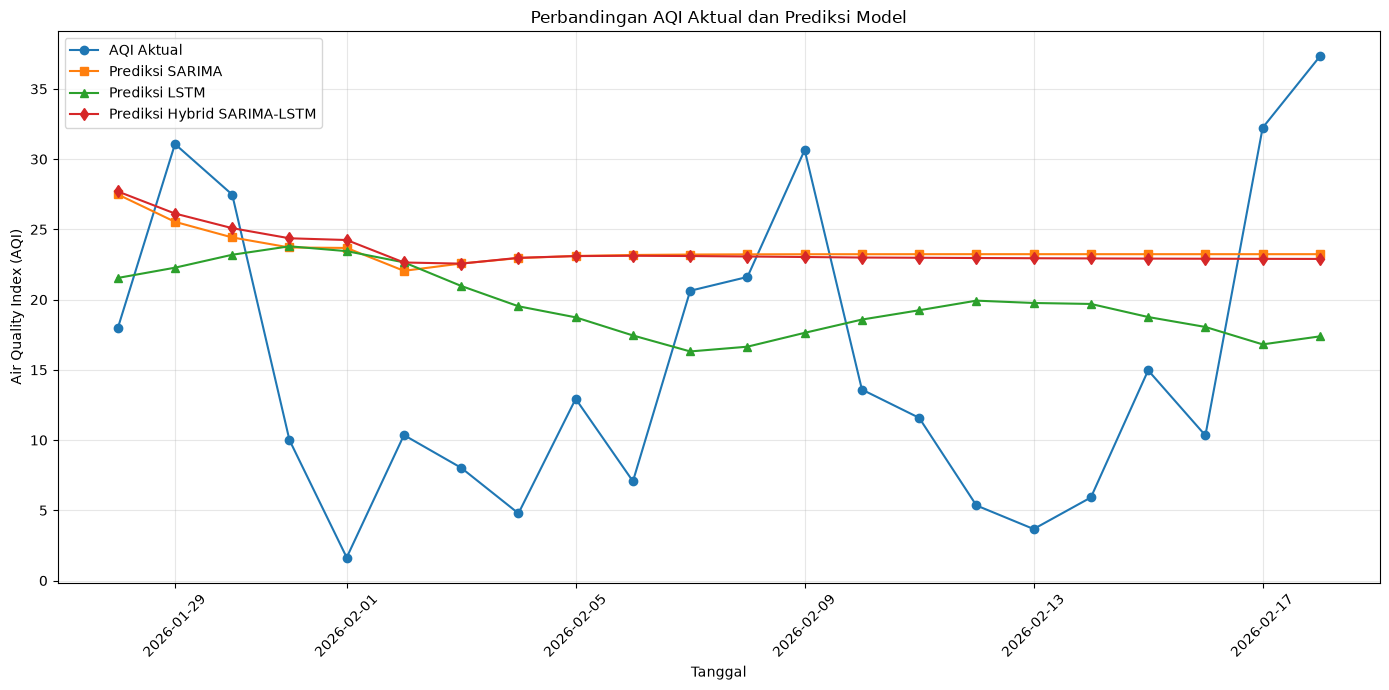

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Memastikan kolom Tanggal menjadi datetime
hasil_lstm["Tanggal"] = pd.to_datetime(hasil_lstm["Tanggal"])

# Menggunakan tanggal sebagai indeks
hasil_lstm_plot = hasil_lstm.set_index("Tanggal")

# Menyamakan periode pengujian
tanggal_test = hasil_hybrid.index
hasil_lstm_plot = hasil_lstm_plot.reindex(tanggal_test)

# Membuat grafik perbandingan
plt.figure(figsize=(14, 7))

plt.plot(
    tanggal_test,
    hasil_hybrid["AQI_Aktual"],
    marker="o",
    label="AQI Aktual"
)

plt.plot(
    tanggal_test,
    hasil_hybrid["Prediksi_SARIMA"],
    marker="s",
    label="Prediksi SARIMA"
)

plt.plot(
    tanggal_test,
    hasil_lstm_plot["AQI_Prediksi"],
    marker="^",
    label="Prediksi LSTM"
)

plt.plot(
    tanggal_test,
    hasil_hybrid["Prediksi_Hybrid"],
    marker="d",
    label="Prediksi Hybrid SARIMA-LSTM"
)

plt.title("Perbandingan AQI Aktual dan Prediksi Model")
plt.xlabel("Tanggal")
plt.ylabel("Air Quality Index (AQI)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
